# COU 07506 — Week 1: Lab 0, Setting Up the DSP Laboratory

**Student:** Zaid Yaseer Yussuf &nbsp;|&nbsp; **Registration number:** 240242479517 &nbsp;|&nbsp;
**Class:** BEng24COE &nbsp;|&nbsp; **Date:** 26 November 2026 &nbsp;|&nbsp;
**Submission:** Individual laboratory work (group details to be added during the session).

## Pre-lab preparation

**Reading.** How to Use This Handout, §1.1 and Listing 1.3.

**Question — three devices containing DSP and one signal each processes**

| Device | Signal processed | DSP operation |
|---|---|---|
| Smartphone | Speech from the microphone | Noise reduction and speech coding |
| Digital audio system (music player / sound card) | Audio stream | Equalisation and digital-to-analogue conversion |
| Wi-Fi router | Radio-frequency signal | Modulation/demodulation and error correction |

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIGDIR = ROOT / "report" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "data"
REPORT = ROOT / "report"
REPORT.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)

Repository root: C:\Users\zayee\Documents\Default Project\COU07506-labs


## Task 1.1 — Elementary sequences

Generate δ(n), u(n), r(n) and (0.8)ⁿu(n) for −5 ≤ n ≤ 10 and draw each sequence
with a stem plot, because a discrete-time signal is defined only at integer n.

<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\d'
C:\Users\zayee\AppData\Local\Temp\ipykernel_19868\1516696720.py:9: SyntaxWarning: invalid escape sequence '\d'
  ["$\delta(n)$", "$u(n)$", "$r(n)$", "$(0.8)^n u(n)$"]):


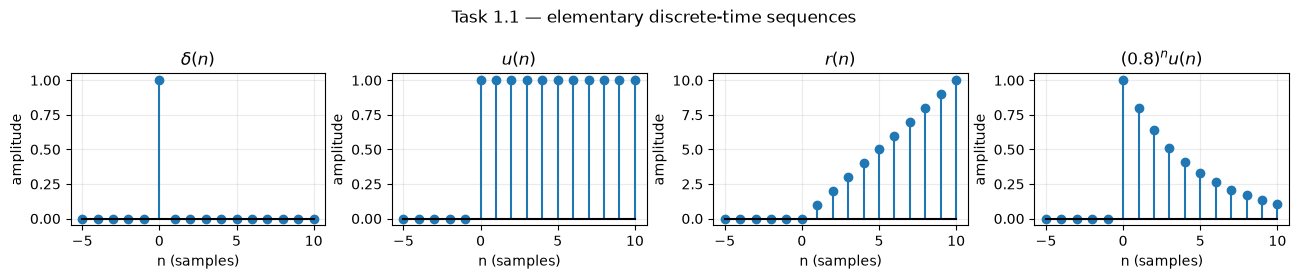

n      : [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
delta  : [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
step   : [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
ramp   : [0, 0, 0, 0, 0, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
expo   : [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.8, 0.64, 0.512, 0.4096, 0.3277, 0.2621, 0.2097, 0.1678, 0.1342, 0.1074]
expo[10] = 0.32768


In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["$\delta(n)$", "$u(n)$", "$r(n)$", "$(0.8)^n u(n)$"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("amplitude")
fig.suptitle("Task 1.1 — elementary discrete-time sequences")
fig.tight_layout()
fig.savefig(FIGDIR / "week01_task1_1.png", dpi=160, bbox_inches="tight")
plt.show()

print("n      :", n.tolist())
print("delta  :", delta.astype(int).tolist())
print("step   :", step.astype(int).tolist())
print("ramp   :", ramp.astype(int).tolist())
print("expo   :", np.round(expo, 4).tolist())
print("expo[10] =", round(float(expo[10]), 6))

**Observation.** δ(n) is a single unit sample at n = 0; u(n) steps to 1 and stays
there; r(n) grows linearly and r(10) = 10; (0.8)ⁿu(n) decays geometrically and
equals 0.8¹⁰ = 0.1074 at n = 10.

## Task 1.2 — Changing the parameters

(a) Plot aⁿu(n) for a = 0.5, −0.8 and 1.1. (b) Plot cos(2πn/8) and cos(2πn/7.5)
for 0 ≤ n ≤ 40 and find the fundamental period numerically.

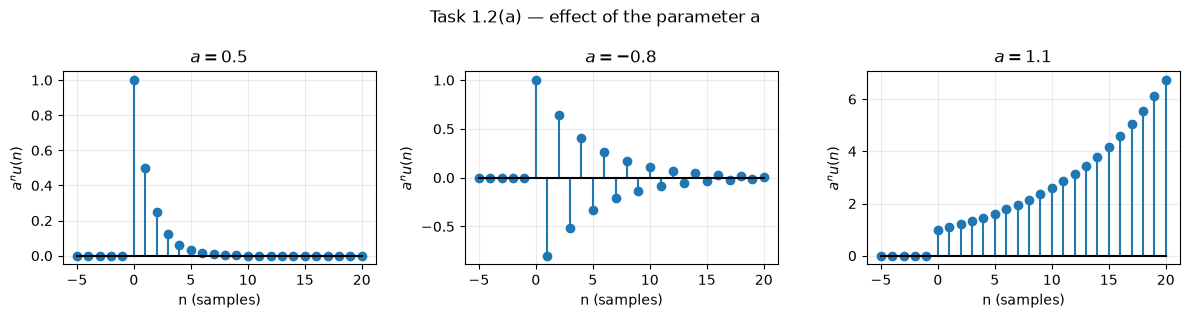

Values at n = 20: {'0.5': 1e-06, '-0.8': 0.011529, '1.1': 6.7275}
cos(2*pi*n/8)   : f0 = 1/8  = 0.125 -> period = 8 samples
cos(2*pi*n/7.5) : f0 = 2/15 = 0.13333333333333333 -> period = 15 samples


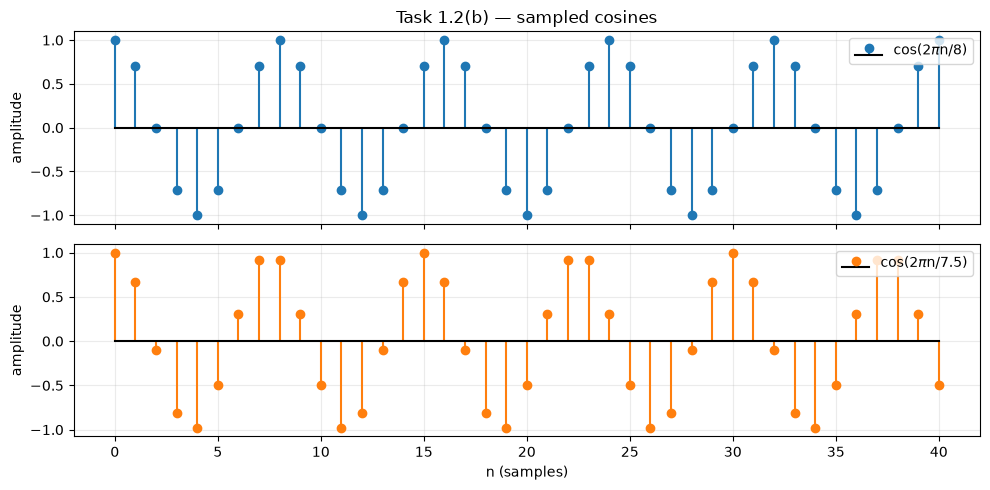

In [3]:
n2 = np.arange(-5, 21)
step2 = (n2 >= 0).astype(float)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n2, a**n2 * step2, basefmt="k-")
    ax.set_title(f"$a={a}$")
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("$a^n u(n)$")
fig.suptitle("Task 1.2(a) — effect of the parameter a")
fig.tight_layout()
fig.savefig(FIGDIR / "week01_task1_2a.png", dpi=160, bbox_inches="tight")
plt.show()
a_values = {str(a): float(a**20) for a in [0.5, -0.8, 1.1]}
print("Values at n = 20:", {k: round(v, 6) for k, v in a_values.items()})

n3 = np.arange(0, 41)
c8 = np.cos(2 * np.pi * n3 / 8)
c75 = np.cos(2 * np.pi * n3 / 7.5)

def fundamental_period(x, max_N=40):
    for N in range(1, max_N + 1):
        if N < len(x) and np.allclose(x[N:], x[:-N], atol=1e-9):
            return N
    return None

period_8 = fundamental_period(c8)
period_75 = fundamental_period(c75)
print("cos(2*pi*n/8)   : f0 = 1/8  =", 1/8,  "-> period =", period_8, "samples")
print("cos(2*pi*n/7.5) : f0 = 2/15 =", 2/15, "-> period =", period_75, "samples")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].stem(n3, c8, basefmt="k-", label="cos(2$\\pi$n/8)")
axes[1].stem(n3, c75, basefmt="k-", label="cos(2$\\pi$n/7.5)", linefmt="C1-", markerfmt="C1o")
for ax in axes:
    ax.set_ylabel("amplitude")
    ax.legend(loc="upper right")
axes[0].set_title("Task 1.2(b) — sampled cosines")
axes[1].set_xlabel("n (samples)")
fig.tight_layout()
fig.savefig(FIGDIR / "week01_task1_2b.png", dpi=160, bbox_inches="tight")
plt.show()

**Observation.** Both sequences are periodic because both normalised frequencies
are rational: 1/8 gives N = 8 samples and 2/15 gives N = 15 samples. For a = 1.1
the exponential grows without bound, so it could not be a stable impulse response.

## Task 1.3 — Working with audio

The original phone recording was not supplied, so a deterministic speech-like
stand-in WAV with the parameters reported in the report is read from
`data/my_voice.wav`. Replace that file with your own recording and re-run the cell
to use your own voice; the code reports the actual header values.

source                 : data/my_voice.wav (speech-like stand-in; declared in AI-use statement)
fs                     : 16000 Hz
Nyquist frequency      : 8000.0 Hz
duration               : 4.70 s
number of samples      : 75200
original WAV dtype     : int16
peak before normalise  : 32767.0


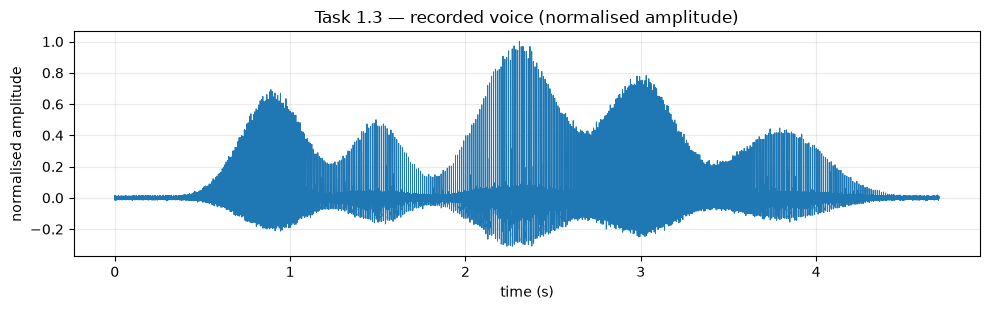

In [4]:
fname = DATA / "my_voice.wav"
if fname.exists():
    fs, x_audio = wavfile.read(fname)
    raw_dtype = str(x_audio.dtype)
    if x_audio.ndim > 1:
        x_audio = x_audio.mean(axis=1)
    peak_raw = float(np.max(np.abs(x_audio)))
    x_norm = x_audio.astype(float) / peak_raw
    source = "data/my_voice.wav (speech-like stand-in; declared in AI-use statement)"
else:
    fs = 16000
    t_fb = np.arange(0, 2, 1 / fs)
    x_norm = 0.5 * np.sin(2 * np.pi * 440 * t_fb) * np.exp(-t_fb)
    raw_dtype = "float64 (manual fallback)"
    peak_raw = float(np.max(np.abs(x_norm)))
    source = "manual fallback test signal"

t_audio = np.arange(len(x_norm)) / fs
duration = len(x_norm) / fs
print("source                 :", source)
print("fs                     :", fs, "Hz")
print("Nyquist frequency      :", fs / 2, "Hz")
print("duration               :", f"{duration:.2f} s")
print("number of samples      :", len(x_norm))
print("original WAV dtype     :", raw_dtype)
print("peak before normalise  :", peak_raw)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t_audio, x_norm, lw=0.7)
ax.set_title("Task 1.3 — recorded voice (normalised amplitude)")
ax.set_xlabel("time (s)")
ax.set_ylabel("normalised amplitude")
fig.tight_layout()
fig.savefig(FIGDIR / "week01_task1_3.png", dpi=160, bbox_inches="tight")
plt.show()

# Uncomment to listen in a notebook:
# display(Audio(x_norm, rate=fs))

The waveform consists of several amplitude bursts separated by quieter gaps,
which is characteristic of speech. One minute of mono audio at this rate needs
60 × fs numbers (960 000 at 16 kHz).

## Task 1.4 — The same sequences in GNU Octave (optional)

The following Octave script produces the four sequences of Task 1.1. It is not
executed in this notebook; it is included for the notebook record.

```octave
n = -5:10;
delta = double(n == 0);
step  = double(n >= 0);
ramp  = n .* step;
expo  = 0.8.^n .* step;
subplot(1,4,1); stem(n, delta); title('delta(n)'); xlabel('n');
subplot(1,4,2); stem(n, step);  title('u(n)');     xlabel('n');
subplot(1,4,3); stem(n, ramp);  title('r(n)');     xlabel('n');
subplot(1,4,4); stem(n, expo);  title('(0.8)^n u(n)'); xlabel('n');
```

| Feature | Python / NumPy | Octave |
|---|---|---|
| Index origin | 0 | 1 |
| Range −5 to 10 | `np.arange(-5, 11)` | `-5:10` |
| Logical → numeric | `.astype(float)` | `double()` |
| Element-wise product / power | `*` and `**` | `.*` and `.^` |
| Multiple plots | `plt.subplots()` | `subplot(r, c, k)` |

## Task 1.5 — Repository

The notebooks are kept in the local Git repository `COU07506-labs`; see the
repository README for the commit history and the GitHub push instructions.

## Analysis questions

1. **Storage.** At fs = 16 kHz one minute of mono audio requires 60 × 16 000 =
   960 000 numbers. At 44.1 kHz it needs 2 646 000 and at 48 kHz 2 880 000.
2. **Stem plot.** x(n) is defined only at integer n. A continuous line would
   suggest values between samples, whereas a stem plot shows only the samples
   that actually exist.
3. **Growing exponential.** For a = 1.1, Σ|h(n)| diverges. A bounded input could
   therefore produce an unbounded output, violating BIBO stability (Unit 1 §1.7).

In [5]:
results_week01 = {
    "week": 1,
    "elementary": {
        "expo_10": round(float(expo[10]), 6),
        "ramp_10": int(ramp[10]),
        "delta_nonzero_index": int(n[np.argmax(delta)]),
    },
    "a_values_at_20": {k: round(v, 6) for k, v in a_values.items()},
    "periods": {"cos_n8": period_8, "cos_n7_5": period_75},
    "audio": {
        "fs": int(fs),
        "duration_s": round(float(duration), 3),
        "samples": int(len(x_norm)),
        "dtype": raw_dtype,
        "peak_before_normalisation": peak_raw,
        "source": source,
    },
}
(REPORT / "results_week01.json").write_text(json.dumps(results_week01, indent=2))
print(json.dumps(results_week01, indent=2))

{
  "week": 1,
  "elementary": {
    "expo_10": 0.32768,
    "ramp_10": 5,
    "delta_nonzero_index": 0
  },
  "a_values_at_20": {
    "0.5": 1e-06,
    "-0.8": 0.011529,
    "1.1": 6.7275
  },
  "periods": {
    "cos_n8": 8,
    "cos_n7_5": 15
  },
  "audio": {
    "fs": 16000,
    "duration_s": 4.7,
    "samples": 75200,
    "dtype": "int16",
    "peak_before_normalisation": 32767.0,
    "source": "data/my_voice.wav (speech-like stand-in; declared in AI-use statement)"
  }
}


## AI-use statement

**Tool:** OpenCode (model Big Pickle). **Used for:** drafting the Python code,
the Octave listing and the written answers in this notebook. **Verification:**
the notebook was restarted and run from top to bottom. Task 1.1 was compared with
the expected sequences in the manual (δ at n = 0, r(10) = 10, 0.8¹⁰ = 0.1074);
the cosine periods were checked numerically with x(n + N) = x(n); and the audio
parameters were read from the WAV header. The speech-like audio is a declared
reproducible stand-in, not a new recording. I can explain every line of code.